# Groupe 4 · Santé publique
## Les paramètres cliniques et biologiques permettent-ils de distinguer les patients avec ou sans maladie rénale chronique ?

**Données** : UCI Chronic Kidney Disease, 400 patients d'un hôpital indien (2015), 19 mesures cliniques et biologiques, et le diagnostic.

⚠ **Ce prototype est un outil d'apprentissage. Il ne sert jamais à poser un diagnostic.**

**Déroulé**
- **Partie A · Explorer et nettoyer les données** (étapes 1 à 10) : erreurs de saisie, valeurs manquantes, valeurs impossibles, valeurs aberrantes, corrélations
- **Partie B · Construire les modèles** (étapes 11 à 14)
- **Partie C · Analyser les résultats** (étapes 15 à 21) : sensibilité, spécificité, règle clinique simple, choix de traitement des manquants, résultat trop beau
- **Partie D · Conclure** (étapes 22 et 23)

*Source : Rubini L., Soundarapandian P., Eswaran P. (2015). Chronic Kidney Disease, UCI Machine Learning Repository.*

# Partie A · Explorer et nettoyer les données

## Étape 1 · Installer et importer les outils

In [1]:
# Installe les trois bibliothèques utilisées dans ce notebook (déjà présentes dans Colab : l'installation est alors immédiate).
# Si le message « you may need to restart the kernel » apparaît, on peut l'ignorer.
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## Étape 2 · Charger les données

In [3]:
import os

# Les fichiers nécessaires : ils doivent être dans le même dossier que ce notebook.
fichiers = ["maladie_renale.csv"]

# Dans Google Colab : si un fichier manque, une fenêtre s'ouvre pour l'envoyer depuis votre ordinateur.
if not all(os.path.exists(f) for f in fichiers):
    from google.colab import files
    files.upload()

donnees = pd.read_csv("maladie_renale.csv")
donnees.head()

,age,tension,densite_urinaire,albumine_urines,sucre_urines,glycemie,uree,creatinine,sodium,potassium,hemoglobine,hematocrite,globules_blancs,globules_rouges,hypertension,diabete,appetit,oedemes,anemie,diagnostic
0,48.0,80.0,1.020,1.0,0.0,121.0,36.0,1.2,NaN,NaN,15.4,44.0,7800.0,5.2,yes,yes,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,18.0,0.8,NaN,NaN,11.3,38.0,6000.0,NaN,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,423.0,53.0,1.8,NaN,NaN,9.6,31.0,7500.0,NaN,no,yes,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,117.0,56.0,3.8,111.0,2.5,11.2,32.0,6700.0,3.9,yes,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,106.0,26.0,1.4,NaN,NaN,11.6,35.0,7300.0,4.6,no,no,good,no,no,ckd


**Les unités** : tension en mmHg, glycémie en mg/dL, urée en mg/dL, créatinine en mg/dL, sodium et potassium en mEq/L, hémoglobine en g/dL, hématocrite en %, globules blancs par mm³, globules rouges en millions par mm³. Albumine et sucre urinaires sont notés de 0 à 5.

## Étape 3 · Une erreur se cache dans le diagnostic

In [4]:
donnees["diagnostic"].value_counts()

diagnostic
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64

Trois valeurs au lieu de deux ! Deux patients sont notés « ckd » suivi d'un caractère invisible (une tabulation). Sans correction, le modèle croirait qu'il existe une troisième catégorie. `str.strip()` retire les espaces et caractères invisibles.

In [5]:
donnees["diagnostic"] = donnees["diagnostic"].str.strip()
donnees["diagnostic"].value_counts()

diagnostic
ckd       250
notckd    150
Name: count, dtype: int64

In [6]:
# Même nettoyage pour les colonnes oui / non, puis transformation en 1 / 0
for colonne in ["hypertension", "diabete", "oedemes", "anemie"]:
    donnees[colonne] = (donnees[colonne].str.strip() == "yes").astype(int)

donnees["appetit_faible"] = (donnees["appetit"].str.strip() == "poor").astype(int)
donnees["malade"] = (donnees["diagnostic"] == "ckd").astype(int)    # 1 = maladie rénale chronique (MRC)

## Étape 4 · Statistiques descriptives

In [7]:
mesures = ["age", "tension", "densite_urinaire", "albumine_urines", "sucre_urines", "glycemie", "uree", "creatinine",
           "sodium", "potassium", "hemoglobine", "hematocrite", "globules_blancs", "globules_rouges"]

donnees[mesures].describe().round(2)

,age,tension,densite_urinaire,albumine_urines,sucre_urines,glycemie,uree,creatinine,sodium,potassium,hemoglobine,hematocrite,globules_blancs,globules_rouges
count,391.00,388.00,353.00,354.00,351.00,356.00,381.00,383.00,313.00,312.00,348.00,329.00,294.00,269.00
mean,51.48,76.47,1.02,1.02,0.45,148.04,57.43,3.07,137.53,4.63,12.53,38.88,8406.12,4.71
std,17.17,13.68,0.01,1.35,1.10,79.28,50.50,5.74,10.41,3.19,2.91,8.99,2944.47,1.03
min,2.00,50.00,1.00,0.00,0.00,22.00,1.50,0.40,4.50,2.50,3.10,9.00,2200.00,2.10
25%,42.00,70.00,1.01,0.00,0.00,99.00,27.00,0.90,135.00,3.80,10.30,32.00,6500.00,3.90
50%,55.00,80.00,1.02,0.00,0.00,121.00,42.00,1.30,138.00,4.40,12.65,40.00,8000.00,4.80
75%,64.50,80.00,1.02,2.00,0.00,163.00,66.00,2.80,142.00,4.90,15.00,45.00,9800.00,5.40
max,90.00,180.00,1.02,5.00,5.00,490.00,391.00,76.00,163.00,47.00,17.80,54.00,26400.00,8.00


**À regarder de près** : le maximum du potassium, le minimum du sodium et le maximum de la créatinine. Ces valeurs sont-elles possibles chez un être humain vivant ?

## Étape 5 · Les valeurs manquantes

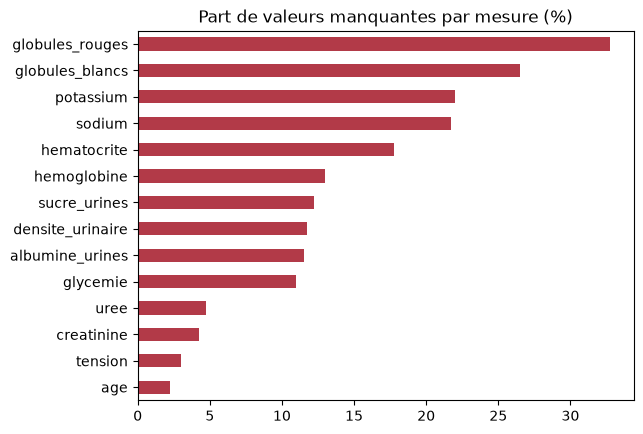

Patients sans aucune valeur manquante : 203 sur 400


In [8]:
part_manquante = (donnees[mesures].isna().mean() * 100).sort_values()

part_manquante.plot(kind="barh", color="#B23A48")
plt.title("Part de valeurs manquantes par mesure (%)")
plt.show()

print("Patients sans aucune valeur manquante :", len(donnees.dropna(subset=mesures)), "sur", len(donnees))

La moitié seulement des patients ont toutes leurs mesures. Retirer les patients incomplets ferait perdre la moitié des données : il faudra un autre choix (étape 11).

## Étape 6 · Les valeurs impossibles

Avant toute statistique, le **bon sens clinique**. Quelques repères : potassium sanguin habituel 3,5 à 5 mEq/L, sodium 135 à 145 mEq/L.

In [9]:
print("Potassium supérieur à 10 mEq/L :")
print(donnees[donnees["potassium"] > 10][["age", "potassium", "sodium", "creatinine", "diagnostic"]])
print()
print("Sodium inférieur à 100 mEq/L :")
print(donnees[donnees["sodium"] < 100][["age", "potassium", "sodium", "creatinine", "diagnostic"]])

Potassium supérieur à 10 mEq/L :
      age  potassium  sodium  creatinine diagnostic
61   67.0       39.0   163.0        32.0        ckd
128  52.0       47.0   133.0         5.6        ckd

Sodium inférieur à 100 mEq/L :
     age  potassium  sodium  creatinine diagnostic
21  60.0        NaN     4.5        76.0        ckd


Un potassium de 39 ou 47 mEq/L, ou un sodium de 4,5 mEq/L, sont **incompatibles avec la vie** : ce sont presque sûrement des erreurs de saisie (une virgule déplacée : 4,7 et 145 ?). On ne peut pas deviner la bonne valeur : on les remplace par « inconnue » (`np.nan`).

In [10]:
donnees.loc[donnees["potassium"] > 10, "potassium"] = np.nan
donnees.loc[donnees["sodium"] < 100, "sodium"] = np.nan

print("Potassium maximal après correction :", donnees["potassium"].max())
print("Sodium minimal après correction :", donnees["sodium"].min())

Potassium maximal après correction : 7.6
Sodium minimal après correction : 104.0


## Étape 7 · Les valeurs aberrantes statistiques

**La règle des quartiles (ou règle de Tukey)**, la plus utilisée pour repérer des valeurs aberrantes :
- Q1 = la valeur sous laquelle se trouvent 25 % des observations ; Q3 = celle sous laquelle se trouvent 75 % ;
- l'écart interquartile vaut Q3 − Q1 ;
- une valeur est dite **aberrante** si elle est en dessous de Q1 − 1,5 × écart ou au-dessus de Q3 + 1,5 × écart.

Attention : *aberrant* veut dire *inhabituel*, pas forcément *faux*. Chaque valeur repérée se discute avec la connaissance du terrain.

In [11]:
q1 = donnees["creatinine"].quantile(0.25)
q3 = donnees["creatinine"].quantile(0.75)
limite_haute = q3 + 1.5 * (q3 - q1)
print("Créatinine : Q1 =", q1, " Q3 =", q3, " limite haute =", round(limite_haute, 2), "mg/dL")

creatinine_elevee = donnees[donnees["creatinine"] > limite_haute]
print("Patients au-dessus de la limite :", len(creatinine_elevee))
print("Dont patients avec MRC :", creatinine_elevee["malade"].sum())

donnees.nlargest(5, "creatinine")[["age", "creatinine", "uree", "hemoglobine", "diagnostic"]]

Créatinine : Q1 = 0.9  Q3 = 2.8  limite haute = 5.65 mg/dL
Patients au-dessus de la limite : 51
Dont patients avec MRC : 51


,age,creatinine,uree,hemoglobine,diagnostic
21,60.0,76.0,180.0,10.9,ckd
148,69.0,48.1,26.0,NaN,ckd
61,67.0,32.0,391.0,NaN,ckd
6,68.0,24.0,54.0,12.4,ckd
193,32.0,18.1,223.0,5.5,ckd


**Décision.** La règle signale une cinquantaine de patients, tous malades : ce sont des insuffisants rénaux graves, pas des erreurs. On les **garde**, ils sont au cœur du sujet.
La créatinine de 76 mg/dL reste douteuse (les valeurs les plus élevées observées en clinique dépassent rarement 20 à 30) : à vérifier dans le dossier source. Ici, on la garde, faute de pouvoir vérifier.

## Étape 8 · Les distributions : une échelle logarithmique pour la créatinine

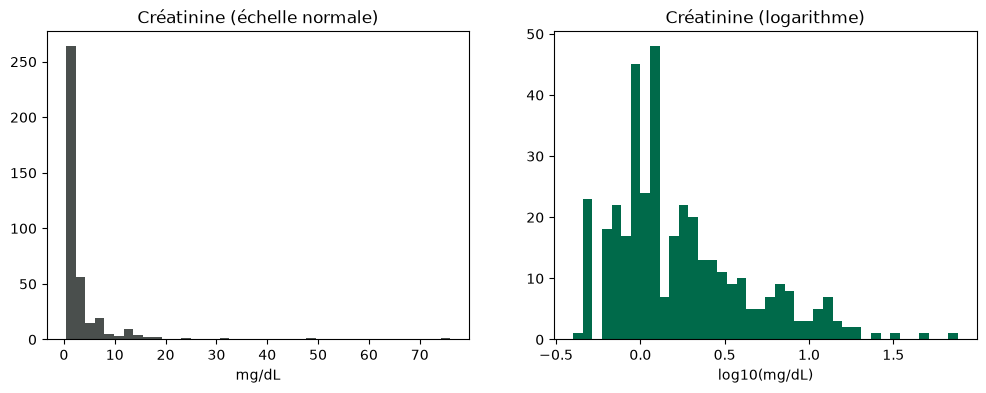

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(donnees["creatinine"].dropna(), bins=40, color="#4A4F4D")
axes[0].set_title("Créatinine (échelle normale)")
axes[0].set_xlabel("mg/dL")
axes[1].hist(np.log10(donnees["creatinine"].dropna()), bins=40, color="#006A4A")
axes[1].set_title("Créatinine (logarithme)")
axes[1].set_xlabel("log10(mg/dL)")
plt.show()

À gauche, presque tout est écrasé près de zéro. Le logarithme « étire » les petites valeurs et rapproche les grandes : on voit mieux la forme de la distribution.

## Étape 9 · Comparer les deux groupes

In [13]:
comparaison = donnees.groupby("diagnostic")[mesures].median().T.round(2)
comparaison.columns = ["Médiane MRC", "Médiane sans MRC"]
comparaison

,Médiane MRC,Médiane sans MRC
age,59.00,46.00
tension,80.00,70.00
densite_urinaire,1.01,1.02
albumine_urines,2.00,0.00
sucre_urines,0.00,0.00
glycemie,143.50,107.50
uree,53.00,33.00
creatinine,2.25,0.90
sodium,136.00,141.00
potassium,4.30,4.50


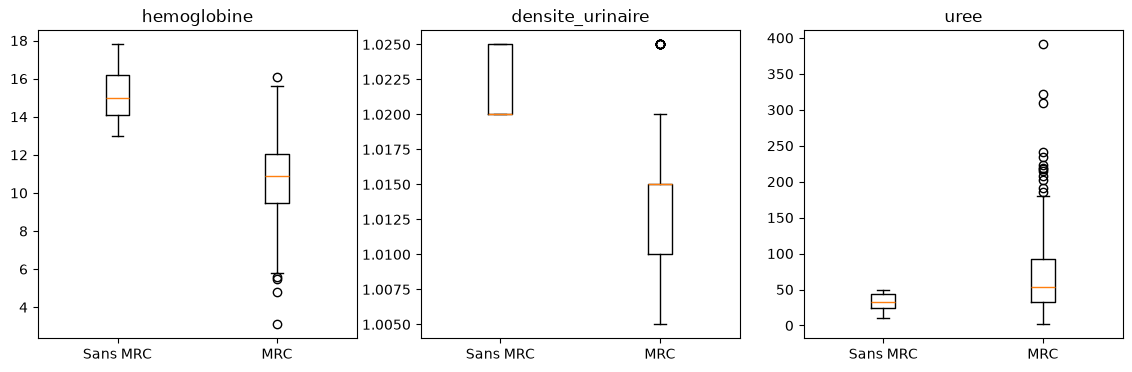

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axe, mesure in zip(axes, ["hemoglobine", "densite_urinaire", "uree"]):
    axe.boxplot([donnees[donnees["malade"] == 0][mesure].dropna(), donnees[donnees["malade"] == 1][mesure].dropna()])
    axe.set_xticks([1, 2])
    axe.set_xticklabels(["Sans MRC", "MRC"])
    axe.set_title(mesure)
plt.show()

## Étape 10 · Les corrélations

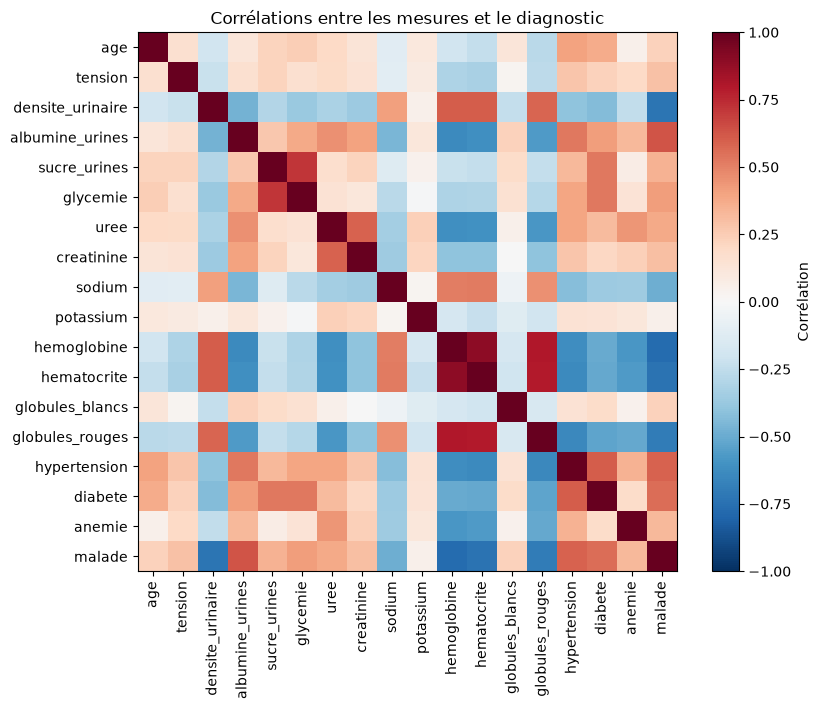

In [15]:
correlations = donnees[mesures + ["hypertension", "diabete", "anemie", "malade"]].corr()      # corrélation entre chaque paire de colonnes (de -1 à 1)

plt.figure(figsize=(9, 7))
plt.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)    # rouge = varient ensemble, bleu = en sens contraire
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations)), correlations.columns)
plt.title("Corrélations entre les mesures et le diagnostic")
plt.show()

**À regarder** : l'hémoglobine et l'hématocrite sont très corrélées (elles mesurent presque la même chose). La dernière ligne, `malade`, montre les mesures les plus liées au diagnostic.

# Partie B · Construire les modèles

## Étape 11 · Préparer les données

Pour garder tous les patients, on remplace chaque valeur manquante par la **médiane** de sa colonne (la valeur du milieu). Ce choix simple sera discuté à l'étape 19.

In [16]:
colonnes = mesures + ["hypertension", "diabete", "appetit_faible", "oedemes", "anemie"]

X = donnees[colonnes].fillna(donnees[colonnes].median())   # valeurs manquantes remplacées par la médiane
y = donnees["malade"]

## Étape 12 · Séparer apprentissage et test

In [17]:
X_apprentissage, X_test, y_apprentissage, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print("Patients pour apprendre :", len(X_apprentissage))
print("Patients pour tester :", len(X_test))

Patients pour apprendre : 280
Patients pour tester : 120


## Étape 13 · Premier modèle : la régression logistique

Les mesures n'ont pas la même échelle (urée en dizaines, densité urinaire autour de 1,02) : on les remet d'abord à la même échelle.

In [18]:
logistique = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
logistique.fit(X_apprentissage, y_apprentissage)

predictions_logistique = logistique.predict(X_test)
print("Bonnes réponses (régression logistique) :", round(accuracy_score(y_test, predictions_logistique) * 100, 1), "%")

Bonnes réponses (régression logistique) : 99.2 %


## Étape 14 · Modèle d'IA : la forêt aléatoire

In [19]:
foret = RandomForestClassifier(n_estimators=300, random_state=42)
foret.fit(X_apprentissage, y_apprentissage)

predictions_foret = foret.predict(X_test)
print("Bonnes réponses (forêt aléatoire) :", round(accuracy_score(y_test, predictions_foret) * 100, 1), "%")

Bonnes réponses (forêt aléatoire) : 100.0 %


# Partie C · Analyser les résultats

## Étape 15 · Sensibilité et spécificité

- **Sensibilité** : parmi les patients malades, combien le modèle en repère-t-il ?
- **Spécificité** : parmi les patients non malades, combien en reconnaît-il comme tels ?

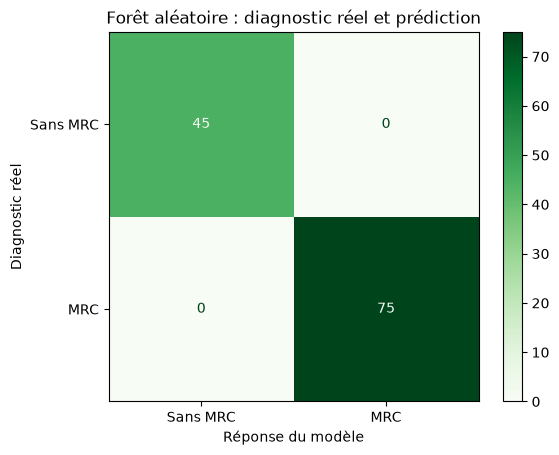

Sensibilité : 75 / 75 = 1.0
Spécificité : 45 / 45 = 1.0


In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions_foret, display_labels=["Sans MRC", "MRC"], cmap="Greens")
plt.title("Forêt aléatoire : diagnostic réel et prédiction")
plt.xlabel("Réponse du modèle")
plt.ylabel("Diagnostic réel")
plt.show()

vrais_negatifs, faux_positifs, faux_negatifs, vrais_positifs = confusion_matrix(y_test, predictions_foret).ravel()
print("Sensibilité :", vrais_positifs, "/", vrais_positifs + faux_negatifs, "=", round(vrais_positifs / (vrais_positifs + faux_negatifs), 2))
print("Spécificité :", vrais_negatifs, "/", vrais_negatifs + faux_positifs, "=", round(vrais_negatifs / (vrais_negatifs + faux_positifs), 2))

## Étape 16 · Le patient mal classé par la régression logistique

In [21]:
mal_classes = X_test[predictions_logistique != y_test]
print("Patients mal classés par la régression logistique :", len(mal_classes))
mal_classes[["age", "tension", "creatinine", "hemoglobine", "densite_urinaire", "albumine_urines", "hypertension", "diabete"]]

Patients mal classés par la régression logistique : 1


,age,tension,creatinine,hemoglobine,densite_urinaire,albumine_urines,hypertension,diabete
102,17.0,60.0,2.1,13.9,1.01,0.0,0,0


**À discuter** : en regardant ses valeurs, ce patient vous paraît-il typique d'une MRC ou non ? Les cas mal classés sont souvent les cas cliniquement ambigus.

## Étape 17 · Comparer à une règle clinique simple

Un modèle complexe n'a d'intérêt que s'il fait mieux qu'une règle simple, par exemple : *créatinine supérieure à 1,2 mg/dL*.

In [22]:
regle = (X_test["creatinine"] > 1.2).astype(int)

vn, fp, fn, vp = confusion_matrix(y_test, regle).ravel()
print("Règle « créatinine > 1,2 » :")
print("  bonnes réponses :", round(accuracy_score(y_test, regle) * 100, 1), "%")
print("  sensibilité :", round(vp / (vp + fn), 2), "  spécificité :", round(vn / (vn + fp), 2))

Règle « créatinine > 1,2 » :
  bonnes réponses : 86.7 %
  sensibilité : 0.79   spécificité : 1.0


## Étape 18 · Ce qui compte pour le modèle

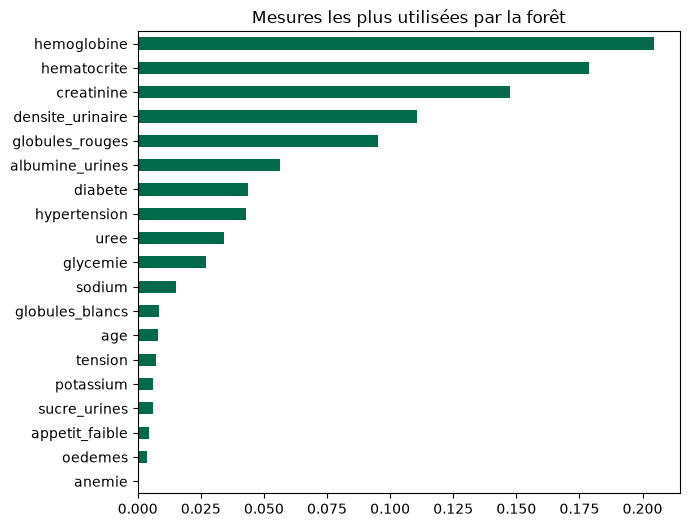

In [23]:
importance = pd.Series(foret.feature_importances_, index=colonnes).sort_values()
importance.plot(kind="barh", color="#006A4A", figsize=(7, 6))
plt.title("Mesures les plus utilisées par la forêt")
plt.show()

In [24]:
# Un modèle avec seulement les trois mesures les plus importantes
trois = list(importance.tail(3).index)
foret_trois = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_apprentissage[trois], y_apprentissage)
print("Avec 3 mesures", trois, ":", round(accuracy_score(y_test, foret_trois.predict(X_test[trois])) * 100, 1), "%")

Avec 3 mesures ['creatinine', 'hematocrite', 'hemoglobine'] : 91.7 %


## Étape 19 · Le choix de traitement des valeurs manquantes

Comparons deux choix : remplacer par la médiane (ce que nous avons fait) ou garder seulement les patients complets.

In [25]:
complets = donnees.dropna(subset=colonnes)
print("Patients complets :", len(complets), "dont", complets["malade"].sum(), "avec MRC et", (complets["malade"] == 0).sum(), "sans MRC")

decoupage = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)      # 5 parts, après avoir mélangé les patients
scores_mediane = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42), X, y, cv=decoupage)
scores_complets = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42), complets[colonnes], complets["malade"], cv=decoupage)
print("Médiane, 5 essais :", (scores_mediane * 100).round(1))
print("Patients complets, 5 essais :", (scores_complets * 100).round(1))

Patients complets : 202 dont 78 avec MRC et 124 sans MRC


Médiane, 5 essais : [ 98.8 100.   98.8  97.5 100. ]
Patients complets, 5 essais : [100.   97.6 100.  100.  100. ]


**À regarder** : parmi les patients complets, la proportion de malades a beaucoup changé. Les patients sans MRC ont plus souvent tous leurs examens… Le choix de traitement des manquants modifie la population étudiée.

## Étape 20 · Un résultat trop beau pour être vrai ?

Presque 100 % de bonnes réponses : en médecine, c'est un **signal d'alerte**, pas une victoire.

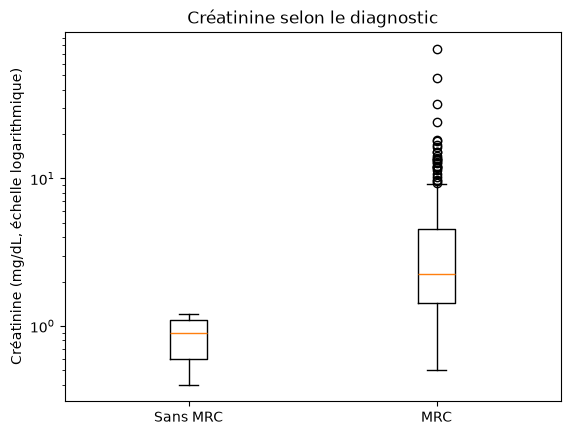

Créatinine maximale chez les patients sans MRC : 1.2 mg/dL


In [26]:
sans_mrc = donnees[donnees["malade"] == 0]["creatinine"].dropna()
avec_mrc = donnees[donnees["malade"] == 1]["creatinine"].dropna()

plt.boxplot([sans_mrc, avec_mrc])
plt.xticks([1, 2], ["Sans MRC", "MRC"])
plt.yscale("log")
plt.ylabel("Créatinine (mg/dL, échelle logarithmique)")
plt.title("Créatinine selon le diagnostic")
plt.show()

print("Créatinine maximale chez les patients sans MRC :", sans_mrc.max(), "mg/dL")

Aucun patient « sans MRC » n'a de créatinine élevée : ces patients ont manifestement été **choisis en bonne santé**. Les deux groupes sont donc très faciles à séparer.
Dans une vraie consultation, beaucoup de patients se situent entre les deux : le modèle y ferait bien plus d'erreurs. **Un bon score dit d'abord quelque chose de la façon dont les données ont été recueillies.**

## Étape 21 · Les probabilités du modèle

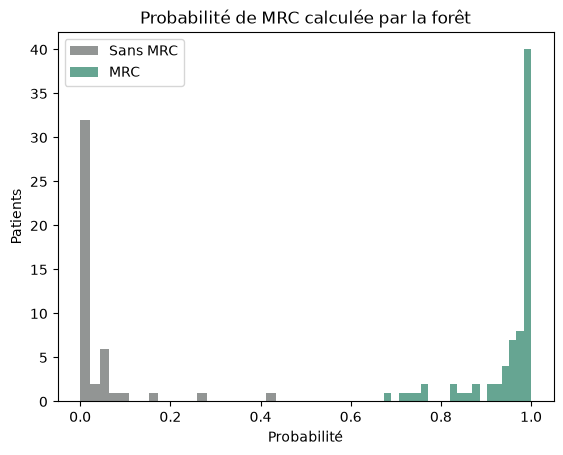

In [27]:
probabilites = foret.predict_proba(X_test)[:, 1]

plt.hist(probabilites[y_test == 0], bins=20, alpha=0.6, color="#4A4F4D", label="Sans MRC")
plt.hist(probabilites[y_test == 1], bins=20, alpha=0.6, color="#006A4A", label="MRC")
plt.title("Probabilité de MRC calculée par la forêt")
plt.xlabel("Probabilité")
plt.ylabel("Patients")
plt.legend()
plt.show()

Deux groupes bien séparés, presque sans chevauchement : c'est la signature de données « trop faciles » (comparez avec le notebook du groupe 1, où les deux histogrammes se chevauchaient fortement).

# Partie D · Conclure

## Étape 22 · Limites

- 400 patients d'un seul hôpital, en Inde, en 2015 ; témoins sélectionnés.
- Valeurs impossibles et manquantes : des choix de nettoyage qui ont un effet sur les résultats et doivent être décrits dans la méthode.
- Aucun usage clinique.